In [1]:
import requests

headers = {
    'sec-ch-ua-platform': '"Windows"',
    'Referer': 'https://www.fotmob.com/en-GB/players/1592161/kieran-morgan',
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/150.0.0.0 Safari/537.36',
    'x-mas': 'eyJib2R5Ijp7InVybCI6Ii9hcGkvZGF0YS9wbGF5ZXJEYXRhP2lkPTE1OTIxNjEiLCJjb2RlIjoxNzg0MzEyNzA0NzMxLCJmb28iOiJwcm9kdWN0aW9uOmE5NjhhMWRhM2UxZGIwZmY2ZjFlZjE4YzNlYjFjZTNkZWE0YWViZTYifSwic2lnbmF0dXJlIjoiQjA5RUQ5NTA4OERFOUZGMDc4REY5MTIxQjQ0QUQwMzkifQ==',
    'sec-ch-ua': '"Not;A=Brand";v="8", "Chromium";v="150", "Google Chrome";v="150"',
    'sec-ch-ua-mobile': '?0',
}

params = {
    'id': '1592161',
}

response = requests.get('https://www.fotmob.com/api/data/playerData', params=params, headers=headers)

In [2]:
import os

os.chdir('/content/drive/MyDrive/Football Data Analysis/Kieran Morgan')

In [3]:
import pandas as pd

data = response.json()

for i in data['positionDescription']['positions']:
  pos_label = i['strPos']['label']
  occurences = i['occurences']
  main_pos = i['isMainPosition']

  print(f"Position: {pos_label}, Occurences: {occurences}, Main Position?: {main_pos}")

# km_df = pd.DataFrame(data)

Position: Right Back, Occurences: 3, Main Position?: False
Position: Left Back, Occurences: 1, Main Position?: False
Position: Defensive Midfielder, Occurences: 2, Main Position?: False
Position: Central Midfielder, Occurences: 9, Main Position?: True
Position: Attacking Midfielder, Occurences: 2, Main Position?: False


In [4]:
pos_data = data['positionDescription']['positions']

pos_norm_df = pd.json_normalize(pos_data)
pos_norm_df

pos_df = pos_norm_df[['strPos.label', 'occurences', 'isMainPosition']]
pos_df = pos_df.rename(columns={'strPos.label': 'position'})

pos_df

,position,occurences,isMainPosition
0,Right Back,3,False
1,Left Back,1,False
2,Defensive Midfielder,2,False
3,Central Midfielder,9,True
4,Attacking Midfielder,2,False


In [5]:
# pos_df.to_excel('km_pos_df.xlsx', index=False)

In [84]:
birth_date = data['birthDate']['utcTime'][:10]
birth_date

name = data['name']
name

team = data['primaryTeam']['teamName']
team

details_data = data['playerInformation']
details_norm_df = pd.json_normalize(details_data)
details_df = details_norm_df[['title', 'value.fallback']]
details_df

rows = {'title': ['Name', 'Birth Date', 'Team'], 'value.fallback': [name, birth_date, team]}

rows_df = pd.DataFrame(rows)

details_df = pd.concat([rows_df, details_df])
details_df = details_df.set_index('title')
details_df

,value.fallback
title,
Name,Kieran Morgan
Birth Date,2006-03-17
Team,Queens Park Rangers
Height,185 cm
Shirt,21
Age,20
Country,England
Market value,€1.4m


In [85]:
# details_df.to_excel('km_details_df.xlsx')

In [61]:
match_data = data['recentMatches']

match_norm_df = pd.json_normalize(match_data)
match_norm_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   teamId                   47 non-null     int64  
 1   teamName                 47 non-null     object 
 2   opponentTeamId           47 non-null     int64  
 3   opponentTeamName         47 non-null     object 
 4   isHomeTeam               47 non-null     bool   
 5   id                       47 non-null     int64  
 6   matchPageUrl             47 non-null     object 
 7   leagueId                 47 non-null     int64  
 8   leagueName               47 non-null     object 
 9   stage                    0 non-null      object 
 10  homeScore                47 non-null     int64  
 11  awayScore                47 non-null     int64  
 12  minutesPlayed            47 non-null     int64  
 13  goals                    47 non-null     int64  
 14  assists                  47 

In [78]:
shot_data = data['firstSeasonStats']['shotmap']

shot_norm_df = pd.json_normalize(shot_data)

shot_df = shot_norm_df.iloc[:, [0,2,3,4,7,8,9,10,19,20,32,33,35,36]]
shot_df

# shot_df.to_excel('km_shotmap.xlsx', index=False)

In [79]:
shot_df

,id,eventType,shotType,situation,x,y,min,minAdded,expectedGoals,expectedGoalsOnTarget,onGoalShot.x,onGoalShot.y,blockedX,blockedY
0,2835560633,Goal,RightFoot,RegularPlay,86.138235,26.169687,45,4.0,0.069046,0.236073,3.544974e-01,0.419577,NaN,NaN
1,2838273305,AttemptSaved,LeftFoot,RegularPlay,91.600000,40.301429,30,NaN,0.054915,0.000000,1.040344e+00,0.322751,93.500000,39.292857
2,2860256583,AttemptSaved,RightFoot,RegularPlay,79.218932,44.421146,77,NaN,0.004490,0.000000,7.781085e-01,0.322751,81.246117,44.421146
3,2881938451,Goal,RightFoot,SetPiece,85.601471,18.814522,90,6.0,0.023929,0.020566,6.772487e-01,0.107018,NaN,NaN
4,2911183525,AttemptSaved,RightFoot,FromCorner,83.949029,39.376905,36,NaN,0.017983,0.000000,4.150132e-01,0.322751,93.700000,37.756000
5,2920487841,AttemptSaved,RightFoot,RegularPlay,78.993689,35.753750,24,NaN,0.043076,0.000000,1.242063e+00,0.322751,85.923529,35.067500
6,2920563481,Miss,RightFoot,RegularPlay,76.516019,26.942143,62,NaN,0.016784,0.000000,6.058650e-01,0.677249,NaN,NaN
7,2920612965,AttemptSaved,RightFoot,IndividualPlay,79.669417,28.623095,90,7.0,0.047322,0.000000,5.158730e-01,0.322751,90.500000,30.950000
8,2922093127,Miss,RightFoot,RegularPlay,77.529612,38.200238,26,NaN,0.018658,0.000000,-2.220446e-16,0.040630,NaN,NaN
9,2927237537,Miss,RightFoot,RegularPlay,80.345146,31.712500,33,NaN,0.039078,0.000000,9.679120e-01,0.677249,NaN,NaN


In [80]:
shot_norm_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 37 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     12 non-null     int64  
 1   playerName             12 non-null     object 
 2   eventType              12 non-null     object 
 3   shotType               12 non-null     object 
 4   situation              12 non-null     object 
 5   teamId                 12 non-null     int64  
 6   playerId               12 non-null     int64  
 7   x                      12 non-null     float64
 8   y                      12 non-null     float64
 9   min                    12 non-null     int64  
 10  minAdded               3 non-null      float64
 11  period                 12 non-null     object 
 12  isOwnGoal              12 non-null     bool   
 13  isBlocked              12 non-null     bool   
 14  isOnTarget             12 non-null     bool   
 15  isSavedO

In [35]:
heatmap_data = data['firstSeasonStats']['heatmap']['coordinates']

heatmap_norm_df = pd.json_normalize(heatmap_data)
heatmap_norm_df.describe()
# heatmap_norm_df.to_excel('km_heatmap.xlsx', index=False)

,x,y
count,1057.000000,1057.000000
mean,49.612062,43.442980
std,21.788291,18.203585
min,0.000000,0.000000
25%,34.570000,29.460000
50%,47.520000,47.710000
75%,64.580000,59.280000
max,104.720000,68.000000


In [36]:
!pip install mplsoccer

/usr/local/lib/python3.12/dist-packages/mplsoccer/soccer/_pitch_base.py:287: UserWarning: Pitch length and widths are only used for ['tracab', 'metricasports', 'custom', 'skillcorner', 'secondspectrum'] pitches and will be ignored
  warnings.warn(msg)


(<Figure size 640x480 with 1 Axes>, <Axes: >)

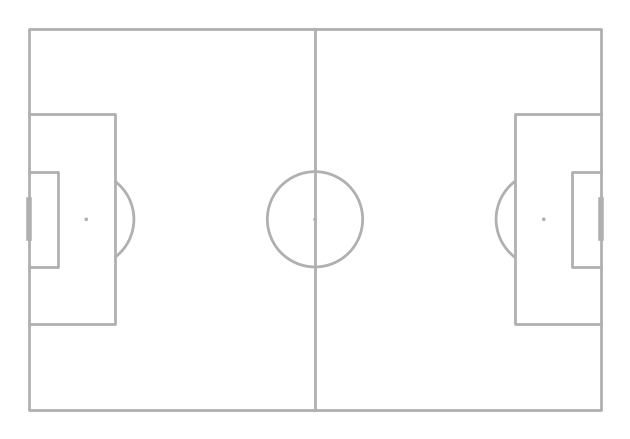

In [65]:
from mplsoccer import Pitch, VerticalPitch

pitch = Pitch(half=False, pitch_length=105, pitch_width=68)
pitch.draw()

(<Figure size 640x480 with 1 Axes>, <Axes: >)

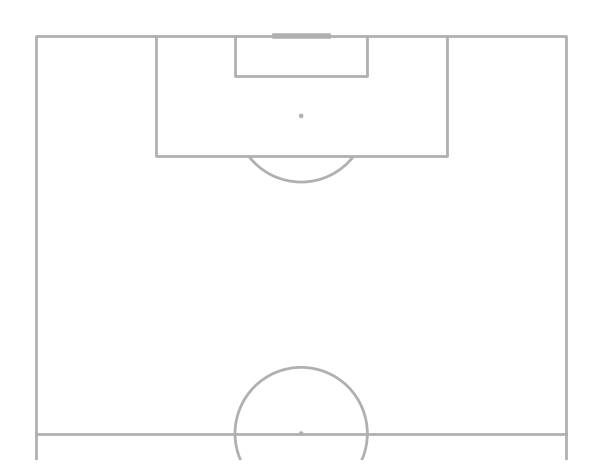

In [66]:
shotmap_pitch = VerticalPitch(half=True)
shotmap_pitch.draw()

In [82]:
stats_data = pd.DataFrame()

for i in range(len(data['firstSeasonStats']['statsSection']['items'])):
  new_data = pd.DataFrame(data['firstSeasonStats']['statsSection']['items'][i]['items'])
  stats_data = pd.concat([stats_data, new_data], ignore_index=True)

stats_data = stats_data[stats_data['percentileRankPer90'] > 46]

stats_data = stats_data.sort_values(by=['percentileRankPer90', 'percentileRank'], ascending=False)

stats_data

,localizedTitleId,per90,percentileRank,percentileRankPer90,statFormat,statValue,title
39,red_cards,0.000000,100.000000,100.000000,number,0,Red cards
11,long_ball_succeeeded_accuracy,61.445783,89.285714,89.285714,percent,61.4,Long ball accuracy
10,long_balls_accurate,3.185288,67.857143,89.285714,number,51,Accurate long balls
0,goals,0.124913,67.857143,81.428571,number,2,Goals
33,dribbled_past,0.499653,62.142857,78.571429,number,8,Dribbled past
8,successful_passes,36.287300,55.000000,62.142857,number,581,Accurate passes
13,big_chance_created_team_title,0.124913,50.714286,61.428571,number,2,Big chances created
22,touches,58.022207,49.285714,54.285714,number,929,Touches
6,assists,0.062457,39.285714,54.285714,number,1,Assists
21,aerials_won_percent,50.000000,53.571429,53.571429,percent,50.0,Aerials won %


In [83]:
# stats_data.to_excel('km_stats.xlsx', index=False)